In [28]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load dataset
df = pd.read_csv("../data/raw/student-mat.csv", sep=";")

print("Dataset loaded:", df.shape)
df.head()

Dataset loaded: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [29]:

# Create academic performance categories

def classify_performance(grade):
    if grade < 10:
        return "High Risk"
    elif grade < 15:
        return "Medium Risk"
    else:
        return "Low Risk"

df["risk_level"] = df["G3"].apply(classify_performance)

print(df["risk_level"].value_counts())

risk_level
Medium Risk    192
High Risk      130
Low Risk        73
Name: count, dtype: int64


In [30]:

# Select input features
X = df[
    [
        "age",
        "studytime",
        "failures",
        "absences",
        "G1",
        "G2",
        "goout",
        "health",
        "freetime"
    ]
]

y = df["risk_level"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 316
Testing samples: 79


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced"
        ))
    ])
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")

    results[name] = {
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    }

    print("\n", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Macro F1:", round(macro_f1, 3))
    print(classification_report(y_test, predictions, zero_division=0))


 Logistic Regression
Accuracy: 88.61 %
Macro F1: 0.895
              precision    recall  f1-score   support

   High Risk       0.81      0.96      0.88        26
    Low Risk       0.88      1.00      0.94        15
 Medium Risk       0.97      0.79      0.87        38

    accuracy                           0.89        79
   macro avg       0.89      0.92      0.89        79
weighted avg       0.90      0.89      0.88        79


 Random Forest
Accuracy: 87.34 %
Macro F1: 0.883
              precision    recall  f1-score   support

   High Risk       0.82      0.88      0.85        26
    Low Risk       0.93      0.93      0.93        15
 Medium Risk       0.89      0.84      0.86        38

    accuracy                           0.87        79
   macro avg       0.88      0.89      0.88        79
weighted avg       0.88      0.87      0.87        79



In [32]:
results_df = pd.DataFrame(results).T
display(results_df)

best_model_name = results_df["Macro F1"].idxmax()
best_model = models[best_model_name]

print("Best Model:", best_model_name)

,Accuracy,Macro F1
Logistic Regression,0.886076,0.894753
Random Forest,0.873418,0.883350


Best Model: Logistic Regression


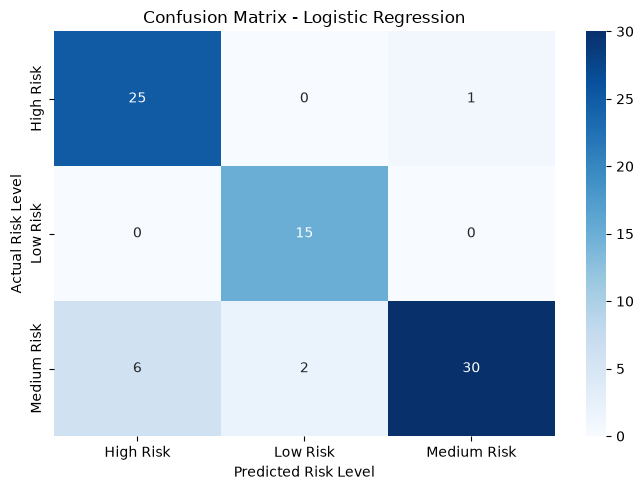

In [33]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

predictions = best_model.predict(X_test)
labels = best_model.classes_

cm = confusion_matrix(y_test, predictions, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Risk Level")
plt.ylabel("Actual Risk Level")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

In [34]:
import joblib
import os

os.makedirs("../dashboard", exist_ok=True)

joblib.dump(best_model, "../dashboard/student_risk_model.pkl")

print("Model saved successfully!")
print("Best Model:", best_model_name)

Model saved successfully!
Best Model: Logistic Regression
